In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

In [3]:
# neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
prefix = '/mnt/staging/' # or 
# prefix = '/scratch/' #for s1n3/4
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
mouse='cm128'

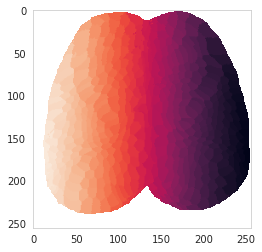

In [4]:
with h5py.File(step_0_root+'idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [5]:
fetch_path = str(PREPARES / "sensory-boop-test") + "/"
sensory_ind = load_pickle(fetch_path+'inferred_brightest_ind_'+mouse)
fetch_path = prefix+'/users/wx2203/new_analysis_locker/pub-locker/heterogeneity/'
M2_ind = load_pickle(fetch_path+'brightest_frontline_ind-'+mouse)

In [6]:
def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))
    plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
    plt.axis('off')
    # plt.colorbar()
    if if_return_map ==True:
        return std_map



In [16]:
f = scipy.io.loadmat(
prefix+'users/wx2203/new_analysis_locker/pub-locker/acadia-figures/efigure2/fig-data/'+'STIM_'+mouse+'_raw.mat',
)

M_jrgeco=f['M_jrgeco']
# M_jrgeco_std=f['M_jrgeco_std']
# M_chbt = f['M_chbt']
# M_chbt_std = f['M_chbt_std']
M_pupil_pc=f['M_pupil_pc']
M_face_pc=f['M_face_pc']
M_rotf = f['M_rotf']
M_rotf_raw = f['M_rotf_raw']
M_body_pc = f['M_body_pc']
M_whisk_vel = f['M_whisk_vel']
M_whisk_vel_norm = f['M_whisk_vel_norm']
M_nose_vel_norm=f['M_nose_vel_norm']
M_nose_vel = f['M_nose_vel']
M_LFP_vel=f['M_LFP_vel']
M_LFP_vel_norm=f['M_LFP_vel_norm']
M_RFP_vel=f['M_RFP_vel']
M_RFP_vel_norm=f['M_RFP_vel_norm']
M_pupil_pc_norm=f['M_pupil_pc_norm']
                            
# M_pupil_p_value=f['M_pupil_p_value']
M_day_label=np.squeeze(f['M_day_label'])
M_is_groom=f['M_is_groom']
M_y_rise_LFP_raw = f['M_y_rise_LFP_raw']
M_y_rise_LFP=f['M_y_rise_LFP']
M_ind=np.squeeze(f['M_ind'])
M_ind_stop=np.squeeze(f['M_ind_stop'])

M_mirrorRFP_vel = f['M_mirrorRFP_vel']
M_mirrorRFP_vel_norm = f['M_mirrorRFP_vel_norm']
M_mirrorLFP_vel = f['M_mirrorLFP_vel']
M_mirrorLFP_vel_norm = f['M_mirrorLFP_vel_norm']
M_mirrorRHP_vel = f['M_mirrorRHP_vel']
M_mirrorRHP_vel_norm = f['M_mirrorRHP_vel_norm']
M_mirrorLHP_vel = f['M_mirrorLHP_vel']
M_mirrorLHP_vel_norm = f['M_mirrorLHP_vel_norm']

T_PRE = 100
T_POST = 100
T = T_PRE+T_POST

for i,label in enumerate(M_day_label):
    M_day_label[i]=label.split(' ')[0]
    
# dlc_joint = load_pickle(str(PREPARES / "epochs-running") + "/"+'final_'+mouse+'_raw_data_joint')
# levelnames = dlc_joint.index.get_level_values(0).drop_duplicates()


# clean up

(13,)


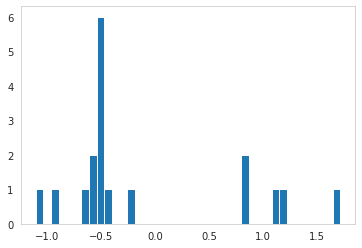

In [17]:

before_running_std = np.mean(M_body_pc[:T_PRE-30,],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0
oo = before_running_std<ss
print(np.where(oo==True)[0].shape)



In [18]:
M_rotf = M_rotf[:,oo]
M_rotf_raw = M_rotf_raw[:,oo]
M_face_pc = M_face_pc[:,oo]
M_body_pc = M_body_pc[:,oo]
M_pupil_pc = M_pupil_pc[:,oo]
M_day_label = M_day_label[oo]
M_jrgeco = M_jrgeco[:,:,oo]
# M_jrgeco_std = M_jrgeco_std[:,:,oo]
# M_chbt = M_chbt[:,:,oo]
# M_chbt_std = M_chbt_std[:,:,oo]
M_whisk_vel = M_whisk_vel[:,oo]
M_whisk_vel_norm = M_whisk_vel_norm[:,oo]
M_nose_vel = M_nose_vel[:,oo]
M_nose_vel_norm = M_nose_vel_norm[:,oo]
# M_pupil_p_value = M_pupil_p_value[:,oo]
M_LFP_vel=M_LFP_vel[:,oo]
M_LFP_vel_norm=M_LFP_vel_norm[:,oo]
M_RFP_vel=M_RFP_vel[:,oo]
M_RFP_vel_norm=M_RFP_vel_norm[:,oo]
M_pupil_pc_norm=M_pupil_pc_norm[:,oo]

M_ind=M_ind[oo]
M_ind_stop=M_ind_stop[oo]

M_is_groom = M_is_groom[:,oo]

M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,oo]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,oo]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,oo]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,oo]

# dlc_joint=dlc_joint.loc[np.squeeze(np.where(oo==True))]


<AxesSubplot:>

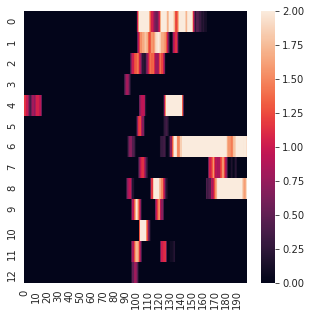

In [19]:
plt.figure(figsize=(5,5))
sns.heatmap(M_body_pc[:,:].transpose(),vmin=-0,vmax=2)


<AxesSubplot:>

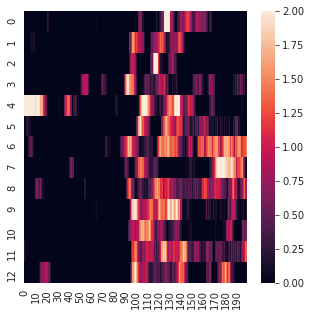

In [20]:
plt.figure(figsize=(5,5))
sns.heatmap(M_face_pc[:,:].transpose(),vmin=-0,vmax=2)


<AxesSubplot:>

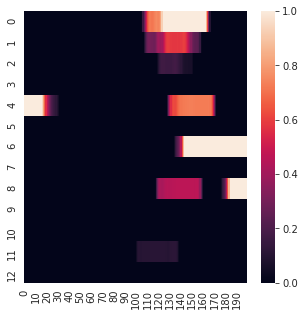

In [21]:
plt.figure(figsize=(5,5))
sns.heatmap(M_rotf[:,:].transpose(),vmin=-0,vmax=1)


(12,)


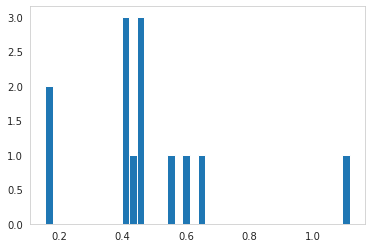

In [22]:

before_running_std = np.std(M_face_pc[:T_PRE-40,],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.7
oo = before_running_std<ss
print(np.where(oo==True)[0].shape)



In [23]:
M_rotf = M_rotf[:,oo]
M_rotf_raw = M_rotf_raw[:,oo]
M_face_pc = M_face_pc[:,oo]
M_body_pc = M_body_pc[:,oo]
M_pupil_pc = M_pupil_pc[:,oo]
M_day_label = M_day_label[oo]
M_jrgeco = M_jrgeco[:,:,oo]
# M_jrgeco_std = M_jrgeco_std[:,:,oo]
# M_chbt = M_chbt[:,:,oo]
# M_chbt_std = M_chbt_std[:,:,oo]
M_whisk_vel = M_whisk_vel[:,oo]
M_whisk_vel_norm = M_whisk_vel_norm[:,oo]
M_nose_vel = M_nose_vel[:,oo]
M_nose_vel_norm = M_nose_vel_norm[:,oo]
# M_pupil_p_value = M_pupil_p_value[:,oo]
M_LFP_vel=M_LFP_vel[:,oo]
M_LFP_vel_norm=M_LFP_vel_norm[:,oo]
M_RFP_vel=M_RFP_vel[:,oo]
M_RFP_vel_norm=M_RFP_vel_norm[:,oo]
M_pupil_pc_norm=M_pupil_pc_norm[:,oo]

M_ind=M_ind[oo]
M_ind_stop=M_ind_stop[oo]

M_is_groom = M_is_groom[:,oo]

M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,oo]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,oo]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,oo]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,oo]

# dlc_joint=dlc_joint.loc[np.squeeze(np.where(oo==True))]


<AxesSubplot:>

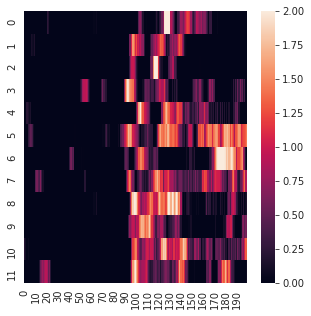

In [24]:
plt.figure(figsize=(5,5))
sns.heatmap(M_face_pc[:,:].transpose(),vmin=-0,vmax=2)


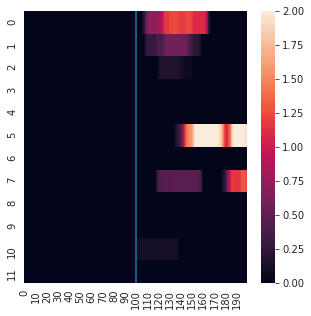

In [25]:
plt.figure(figsize=(5,5))
sns.heatmap(M_rotf[:,:].transpose(),vmin=-0,vmax=2)
plt.axvline(T_PRE)

(12,)


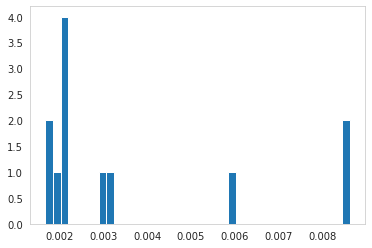

In [26]:

before_running_std = np.std(M_rotf[:T_PRE-40,],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.7
oo = before_running_std<ss
print(np.where(oo==True)[0].shape)



In [27]:
M_rotf = M_rotf[:,oo]
M_rotf_raw = M_rotf_raw[:,oo]
M_face_pc = M_face_pc[:,oo]
M_body_pc = M_body_pc[:,oo]
M_pupil_pc = M_pupil_pc[:,oo]
M_day_label = M_day_label[oo]
M_jrgeco = M_jrgeco[:,:,oo]
# M_jrgeco_std = M_jrgeco_std[:,:,oo]
# M_chbt = M_chbt[:,:,oo]
# M_chbt_std = M_chbt_std[:,:,oo]
M_whisk_vel = M_whisk_vel[:,oo]
M_whisk_vel_norm = M_whisk_vel_norm[:,oo]
M_nose_vel = M_nose_vel[:,oo]
M_nose_vel_norm = M_nose_vel_norm[:,oo]
# M_pupil_p_value = M_pupil_p_value[:,oo]
M_LFP_vel=M_LFP_vel[:,oo]
M_LFP_vel_norm=M_LFP_vel_norm[:,oo]
M_RFP_vel=M_RFP_vel[:,oo]
M_RFP_vel_norm=M_RFP_vel_norm[:,oo]
M_pupil_pc_norm=M_pupil_pc_norm[:,oo]

M_ind=M_ind[oo]
M_ind_stop=M_ind_stop[oo]

M_is_groom = M_is_groom[:,oo]

M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,oo]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,oo]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,oo]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,oo]

# dlc_joint=dlc_joint.loc[np.squeeze(np.where(oo==True))]


# find running ONSET

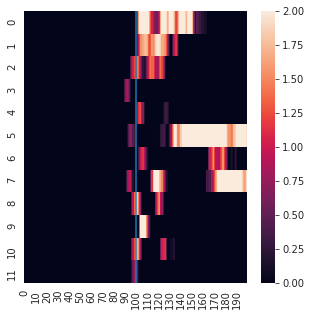

In [28]:
plt.figure(figsize=(5,5))
sns.heatmap(M_body_pc[:,:].transpose(),vmin=-0,vmax=2)
plt.axvline(T_PRE)

In [29]:
M_body_pc.shape

(200, 12)

In [30]:
def shift_2d_array(array_2d, offsets):
    shifted_array = np.zeros_like(array_2d)
    num_rows, num_cols = array_2d.shape

    for i in range(num_rows):
        offset = offsets[i]
        shifted_array[i, max(0, offset):num_cols + min(0, offset)] = array_2d[i, max(0, -offset):num_cols + min(0, -offset)]

    return shifted_array

In [31]:
offsets = []
for i_bout in range(M_body_pc.shape[-1]):
    
    start_stop_ind = start_stop(M_body_pc[:,i_bout]>0.1,True)
    ind_filt = np.abs(start_stop_ind[:,0]-T_PRE)<25
    start_stop_ind = start_stop_ind[ind_filt,:]
    offsets.append(start_stop_ind[0][0]-T_PRE)

offsets=-np.array(offsets)


In [32]:
M_body_pc_shifted = shift_2d_array(M_body_pc.T, offsets).T

<AxesSubplot:>

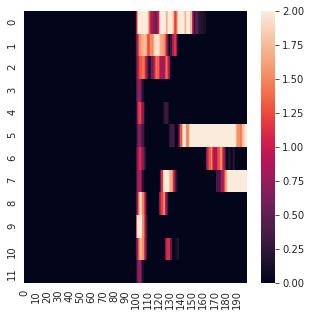

In [33]:
plt.figure(figsize=(5,5))
sns.heatmap(M_body_pc_shifted[:,:].transpose(),vmin=-0,vmax=2)
# plt.axvline(T_PRE)

In [34]:
all_beh_list = ['M_rotf','M_rotf_raw','M_face_pc','M_body_pc','M_pupil_pc','M_whisk_vel',
               'M_whisk_vel_norm','M_nose_vel','M_nose_vel_norm','M_LFP_vel','M_LFP_vel_norm',
               'M_RFP_vel','M_RFP_vel_norm','M_pupil_pc_norm','M_is_groom','M_mirrorRFP_vel_norm',
               'M_mirrorLFP_vel_norm','M_mirrorRHP_vel_norm','M_mirrorLHP_vel_norm']
for beh in all_beh_list:
    exec("{} = shift_2d_array({}.T, offsets).T".format(beh,beh))
    
temp_M_jrgeco = []
for i_region in range(500):
    temp_M_jrgeco.append(shift_2d_array(M_jrgeco[i_region,:,:].T, offsets).T)
M_jrgeco = np.stack(temp_M_jrgeco,axis=0)
M_ind = M_ind - offsets*3
M_ind_stop = M_ind_stop - offsets*3

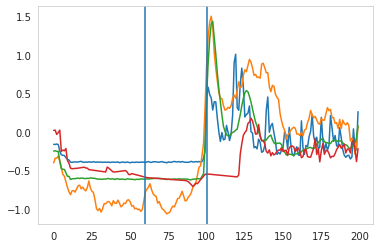

In [35]:
plt.plot(np.mean(M_RFP_vel_norm,-1))
plt.plot(np.mean(M_face_pc,-1))
plt.plot(np.mean(M_body_pc,-1))
plt.plot(np.mean(M_pupil_pc_norm,-1))
plt.axvline(T_PRE)
plt.axvline(T_PRE-40)

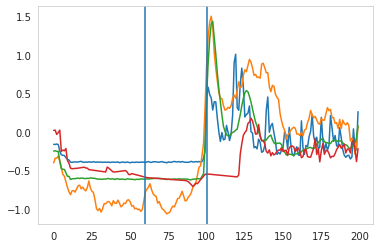

In [36]:
plt.plot(np.mean(M_RFP_vel_norm,-1))
plt.plot(np.mean(M_face_pc,-1))
plt.plot(np.mean(M_body_pc,-1))
plt.plot(np.mean(M_pupil_pc_norm,-1))
plt.axvline(T_PRE)
plt.axvline(T_PRE-40)

# SAVE

In [37]:
scipy.io.savemat(
    prefix+'users/wx2203/new_analysis_locker/pub-locker/acadia-figures/efigure2/fig-data/'+'STIM_'+mouse+'_filt.mat',
                       {'M_jrgeco':M_jrgeco,
                        'M_rotf':M_rotf,
                        'M_rotf_raw':M_rotf_raw,
                        'M_face_pc':M_face_pc,
                        'M_body_pc':M_body_pc,
                        'M_pupil_pc':M_pupil_pc,
                        'M_pupil_pc_norm':M_pupil_pc_norm,
                        # 'M_pupil_p_value':M_pupil_p_value,
                        'M_whisk_vel':M_whisk_vel,
                        'M_whisk_vel_norm':M_whisk_vel_norm,
                        'M_nose_vel':M_nose_vel,
                        'M_nose_vel_norm':M_nose_vel_norm,
                        'M_LFP_vel':M_LFP_vel,
                        'M_LFP_vel_norm':M_LFP_vel_norm,
                        'M_RFP_vel':M_RFP_vel,
                        'M_RFP_vel_norm':M_RFP_vel_norm,
                       'M_day_label':M_day_label,
                        'M_is_groom':M_is_groom,
                       'M_ind':M_ind,
                           'M_ind_stop':M_ind_stop,
                       'M_y_rise_LFP':M_y_rise_LFP,
                       'M_y_rise_LFP_raw':M_y_rise_LFP_raw,
                       'M_mirrorRFP_vel':M_mirrorRFP_vel,
                       'M_mirrorRFP_vel_norm':M_mirrorRFP_vel_norm,
                        'M_mirrorLFP_vel':M_mirrorLFP_vel,
                        'M_mirrorLFP_vel_norm':M_mirrorLFP_vel_norm,
                        'M_mirrorRHP_vel':M_mirrorRHP_vel,
                        'M_mirrorRHP_vel_norm':M_mirrorRHP_vel_norm,
                        'M_mirrorLHP_vel':M_mirrorLHP_vel,
                        'M_mirrorLHP_vel_norm':M_mirrorLHP_vel_norm
                       })


